# Simulate and fit a 2D bead slide

Start with randomly placed 40 nm beads on a plane. Render a 40-frame movie, estimate its PSF and illumination from the pixels, then compare the result with the simulation. The saved plots can be read directly on GitHub.

### Run this notebook

Clone SIMCODE and TorchPSF into sibling directories. From the SIMCODE root, install the Python and Node dependencies in an environment with PyTorch. Open this notebook with that environment and run the cells in order.

```sh
git clone https://github.com/jcnossen/torch-psf ../torch-psf
python -m pip install -e ../torch-psf
python -m pip install jupyter matplotlib
npm ci --prefix ../torch-psf/web
```

The notebook writes its simulated TIFF and calibration outputs to `bead-slide-example/` in the current directory.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tifffile
import torch
import torch_psf
from torch_psf import DenseBeadEstimator
from torch_psf.psfzip import save_zip

examples = Path.cwd() if Path("estimate_bead_slide.py").exists() else Path("examples").resolve()
sys.path.insert(0, str(examples))
from estimate_bead_slide import estimate_modulation

# Reuse the TorchPSF simulation that reproduces the browser's bead-slide example.
torch_repo = Path(torch_psf.__file__).resolve().parents[1]
sys.path.insert(0, str(torch_repo / "study/simcode_random_walk"))
from simcode_bead_movie import OPTICS, simulate

out = Path("bead-slide-example")
out.mkdir(exist_ok=True)
seed, n_frames, n_beads = 17, 40, 1200
device = "cuda" if torch.cuda.is_available() else "cpu"

### 1. Simulate a movie

Each illumination axis has a 200 nm pitch and three phase steps. The exposures repeat A0, A120, A240, B0, B120, B240. The simulator applies XYZ random-walk drift, a shared aberrated vectorial PSF and photon-dependent noise. Bead footprints can overlap.

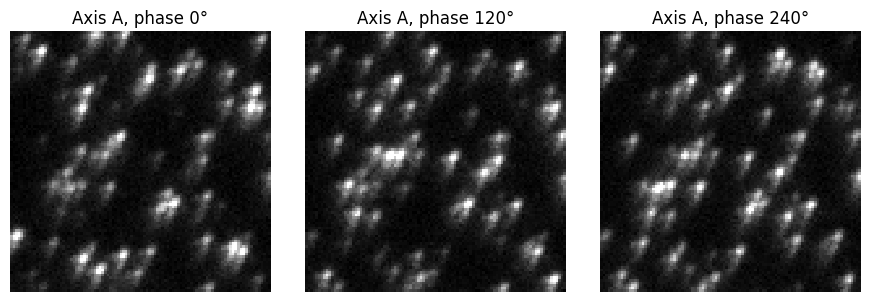

In [2]:
simulate(out, seed=seed, frames=n_frames, device=device, bead_count=n_beads)
movie = tifffile.imread(out / f"{seed}.tif")
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
lo, hi = np.percentile(movie[0], [1, 99.7])
for t, ax in enumerate(axes):
    ax.imshow(movie[t, :100, :100], cmap="gray", vmin=lo, vmax=hi, interpolation="nearest")
    ax.set_title(f"Axis A, phase {120*t}°")
    ax.axis("off")
plt.tight_layout()
plt.show()

### 2. Estimate the PSF, bead intensities and illumination

Give TorchPSF the camera sampling, nominal optics, bead diameter and repeated exposure labels. The estimated bead intensities and XY drift then go into SIMCODE's web modulation estimator. The uniformly random bead field also supports the image-power depth estimate. The simulation truth is opened only after both fits.

In [3]:
optics = dict(OPTICS, diameter_um=0.040, focus_um=0.1)
schedule = dict(axes=2, phases=3, interleaved=False)
exposure_slot = np.arange(len(movie)) % 6
fit = DenseBeadEstimator.fit_movie(movie, exposure_slot, optics=optics, radius=6)
pupil = fit.psf.optic.cfg["calibrated_psf"]
result = estimate_modulation(movie, fit, optics, schedule)

save_zip(str(out / "psf.zip"), pupil)
(out / "modulation.json").write_text(json.dumps(result, indent=2))
print(f"Recovered {len(fit.xy)} bead candidates from {len(movie)} frames.")

Group fit 1 candidates 1094


Exposure 1


Exposure 26


Recovered 1094 bead candidates from 40 frames.


### 3. Compare with the known simulation

The depth and intensity ratio vary across the field. The table uses their values at the field center, where the normalized coordinates are zero. The plots compare pupil coefficients and a horizontal cut through each fitted depth map.

In [4]:
truth = json.loads((out / f"{seed}-truth.json").read_text())
print("Axis   pitch (nm)      angle (deg)      center depth")
print("       true / fit      true / fit       true / fit")
for i, pattern in enumerate(result["patterns"]):
    print(f"{'AB'[i]}      200 / {pattern['pitch_nm']:.1f}     "
          f"{[13, 104][i]:3} / {pattern['orientation_deg']:.1f}       "
          f"{[.84, .88][i]:.2f} / {pattern['depth'][0]:.3f}")
print(f"Center A/B intensity ratio: true 1.12, fitted {result['ratio'][0]:.3f}")

Axis   pitch (nm)      angle (deg)      center depth
       true / fit      true / fit       true / fit
A      200 / 200.0      13 / 13.0       0.84 / 0.846
B      200 / 200.0     104 / 104.0       0.88 / 0.884
Center A/B intensity ratio: true 1.12, fitted 1.122


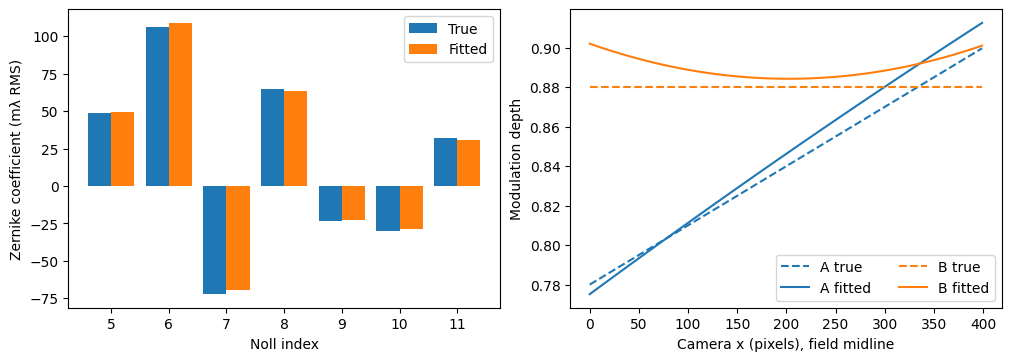

In [5]:
fig, (pax, dax) = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
modes = np.arange(5, 12)
pax.bar(modes - .2, 1000 * np.array(truth["coef"]), .4, label="True")
pax.bar(modes + .2, 1000 * pupil.zcoef.detach().cpu().numpy().ravel(), .4, label="Fitted")
pax.set(xlabel="Noll index", ylabel="Zernike coefficient (mλ RMS)")
pax.legend()

u = np.linspace(-1, 1, 100)
for i, pattern in enumerate(result["patterns"]):
    c = pattern["depth"]
    color = f"C{i}"
    x = (u + 1) / 2 * (movie.shape[2] - 1)
    true = .84 + .06*(2*x/movie.shape[2]-1) if i == 0 else np.full_like(u, .88-.05/movie.shape[1])
    dax.plot(x, true, "--", color=color, label=f"{'AB'[i]} true")
    dax.plot(x, c[0] + c[1]*u + c[3]*u**2, color=color, label=f"{'AB'[i]} fitted")
dax.set(xlabel="Camera x (pixels), field midline", ylabel="Modulation depth")
dax.legend(ncol=2)
plt.show()